# EDA

Narrative length, the most common words and two-word phrases, the ones that go with disputes, and template letters, using the clean text from `load_text()`. The dashed line on the dispute-rate charts is the overall rate (22.6%).

In [1]:
import sys

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from src.data import load_text

FIGURES = "../reports/figures/"

In [2]:
df = load_text()
overall = df["disputed"].mean()
len(df), overall

(149661, np.float64(0.22640500865288887))

In [3]:
df["words"] = df["text"].str.split().str.len()
df["words"].describe().round(1)

count    149661.0
mean        191.4
std         167.5
min           1.0
25%          72.0
50%         136.0
75%         256.0
max        1284.0
Name: words, dtype: float64

## Length by product

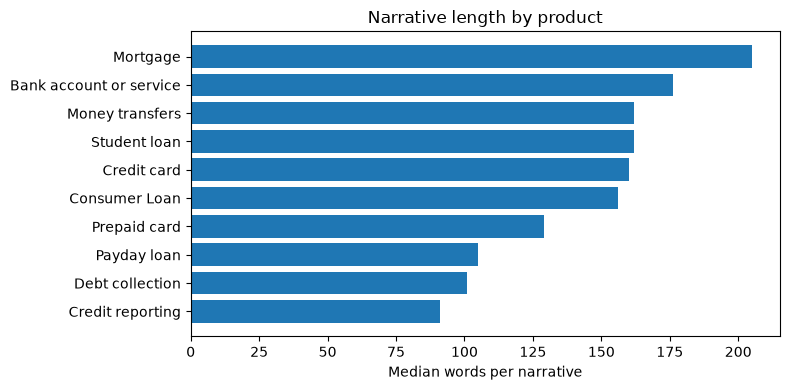

,size,median
product,,
Credit reporting,28329,91.0
Debt collection,36751,101.0
Payday loan,1632,105.0
Prepaid card,1369,129.0
Consumer Loan,8565,156.0
Credit card,17333,160.0
Student loan,9585,162.0
Money transfers,1382,162.0
Bank account or service,13734,176.0


In [4]:
by_product = df.groupby("product")["words"].agg(["size", "median"])
by_product = by_product[by_product["size"] >= 1000].sort_values("median")

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(by_product.index, by_product["median"])
ax.set_xlabel("Median words per narrative")
ax.set_title("Narrative length by product")
fig.tight_layout()
fig.savefig(FIGURES + "words_by_product.png", dpi=150)
plt.show()
by_product

Mortgage narratives are the longest, with a median of 205 words. Credit reporting (91) and debt collection (101) are about half that, and those two products make up 43% of the narratives. Products with fewer than 1,000 narratives are left off the chart.

## Length and disputes

In [5]:
df.groupby("disputed")["words"].median()

disputed
0    129.0
1    163.0
Name: words, dtype: float64

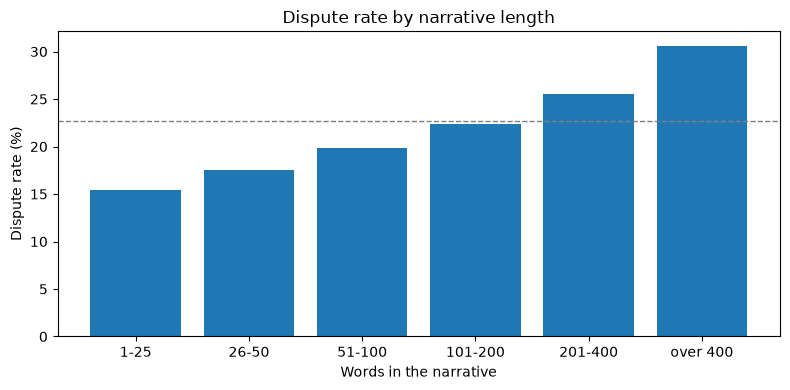

,size,mean
length_band,,
1-25,8157,0.154
26-50,14997,0.176
51-100,33124,0.198
101-200,42502,0.224
201-400,33037,0.256
over 400,17844,0.306


In [6]:
df["length_band"] = pd.cut(
    df["words"],
    [0, 25, 50, 100, 200, 400, 1300],
    labels=["1-25", "26-50", "51-100", "101-200", "201-400", "over 400"],
)
by_length = df.groupby("length_band", observed=True)["disputed"].agg(["size", "mean"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_length.index, by_length["mean"] * 100)
ax.axhline(overall * 100, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Words in the narrative")
ax.set_ylabel("Dispute rate (%)")
ax.set_title("Dispute rate by narrative length")
fig.tight_layout()
fig.savefig(FIGURES + "dispute_rate_by_length.png", dpi=150)
plt.show()
by_length.round(3)

Disputed narratives are longer, with a median of 163 words against 129. The rate goes up with every band, from 15.4% for 25 words or fewer to 30.6% for more than 400.

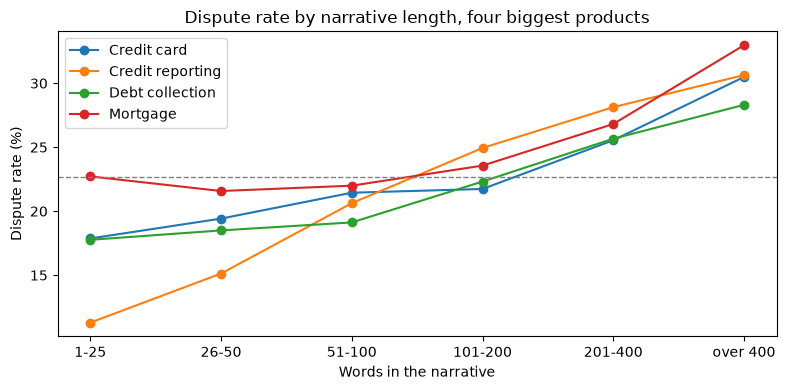

product,Credit card,Credit reporting,Debt collection,Mortgage
length_band,,,,
1-25,0.179,0.113,0.178,0.227
26-50,0.194,0.151,0.185,0.216
51-100,0.214,0.206,0.191,0.220
101-200,0.217,0.249,0.223,0.236
201-400,0.255,0.281,0.257,0.268
over 400,0.305,0.306,0.283,0.330


In [7]:
top4 = df["product"].value_counts().head(4).index
by_length_product = df[df["product"].isin(top4)].pivot_table(
    index="length_band", columns="product", values="disputed", aggfunc="mean", observed=True
)

fig, ax = plt.subplots(figsize=(8, 4))
(by_length_product * 100).plot(ax=ax, marker="o")
ax.axhline(overall * 100, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Words in the narrative")
ax.set_ylabel("Dispute rate (%)")
ax.set_title("Dispute rate by narrative length, four biggest products")
ax.legend(title="")
fig.tight_layout()
fig.savefig(FIGURES + "dispute_rate_by_length_product.png", dpi=150)
plt.show()
by_length_product.round(3)

The pattern holds inside each of the four biggest products. Credit reporting has the steepest climb, from 11.3% to 30.6%. Mortgage stays near 22% up to 100 words and only rises after that, to 33.0%.

## Common words

Each word is counted once per narrative, so the numbers are the share of narratives that contain it. English stop words are left out, and so are words in fewer than 1,500 narratives (1%).

In [8]:
def term_table(ngram_range):
    vectorizer = CountVectorizer(stop_words="english", ngram_range=ngram_range, binary=True, min_df=1500)
    counts = vectorizer.fit_transform(df["text"])
    disputed = (df["disputed"] == 1).to_numpy()
    terms = pd.DataFrame(
        {
            "narratives": np.asarray(counts.sum(axis=0)).ravel(),
            "disputed": np.asarray(counts[disputed].sum(axis=0)).ravel(),
        },
        index=vectorizer.get_feature_names_out(),
    )
    terms["share"] = terms["narratives"] / len(df)
    terms["dispute_rate"] = terms["disputed"] / terms["narratives"]
    return terms


def share_chart(terms, title, filename):
    top = terms.sort_values("share").tail(20)
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.barh(top.index, top["share"] * 100)
    ax.set_xlabel("Narratives with the term (%)")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(FIGURES + filename, dpi=150)
    plt.show()
    return top[["narratives", "share"]].sort_values("share", ascending=False).round(3)

In [9]:
words = term_table((1, 1))
len(words)

1006

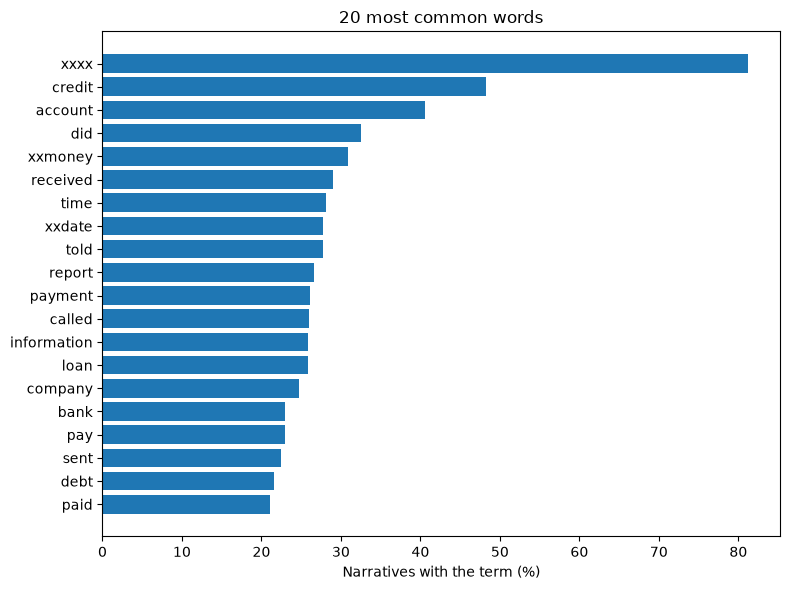

,narratives,share
xxxx,121497,0.812
credit,72206,0.482
account,60786,0.406
did,48728,0.326
xxmoney,46152,0.308
received,43315,0.289
time,42158,0.282
xxdate,41612,0.278
told,41537,0.278
report,39736,0.266


In [10]:
share_chart(words, "20 most common words", "common_words.png")

`xxxx` is in 81% of narratives, and the amount and date tokens are both in the top ten. After those come the subject of the complaint (credit, account, report, payment, loan) and contact with the company (received, told, called, sent).

In [11]:
did = df["text"].str.contains(r"\bdid\b", case=False)
did_not = df["text"].str.contains(r"\bdid (?:not|n't)\b", case=False)
did.sum(), did_not.sum()

(np.int64(48728), np.int64(38081))

`did` is in 33% of narratives, and in 78% of those it's part of "did not". "not" is on the stop-word list, so the negation is lost. The models should be tried with the stop words left in as well.

## Common two-word phrases

In [12]:
phrases = term_table((2, 2))
len(phrases)

275

In [13]:
no_tokens = phrases[~phrases.index.str.contains("xx")]
len(no_tokens)

143

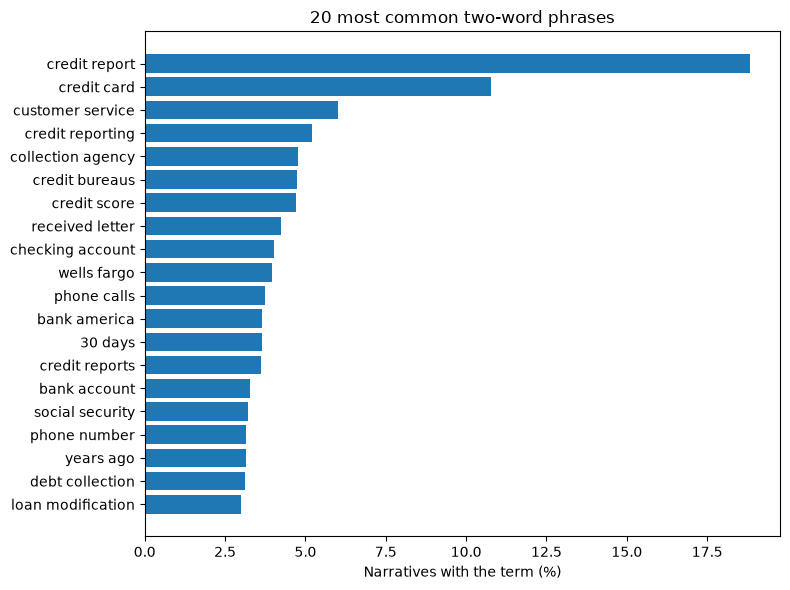

,narratives,share
credit report,28173,0.188
credit card,16119,0.108
customer service,9002,0.060
credit reporting,7769,0.052
collection agency,7158,0.048
credit bureaus,7104,0.047
credit score,7034,0.047
received letter,6363,0.043
checking account,6001,0.040
wells fargo,5930,0.040


In [14]:
share_chart(no_tokens, "20 most common two-word phrases", "common_phrases.png")

Phrases with a redaction token are left out here, otherwise `xxxx xxxx` tops the list. Credit report is in 18.8% of narratives and credit card in 10.8%. Customer service is third at 6.0%. Stop words are dropped before the pairs are made, so "bank america" is Bank of America. It and Wells Fargo are the only companies in the top 20.

## Words and phrases that go with disputes

In [15]:
def rate_chart(terms, title, filename):
    ordered = terms.sort_values("dispute_rate")
    ends = pd.concat([ordered.head(15), ordered.tail(15)])
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.barh(ends.index, ends["dispute_rate"] * 100)
    ax.axvline(overall * 100, color="grey", linestyle="--", linewidth=1)
    ax.set_xlabel("Dispute rate of narratives with the term (%)")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(FIGURES + filename, dpi=150)
    plt.show()
    return ends[["narratives", "dispute_rate"]].sort_values("dispute_rate", ascending=False).round(3)

In [16]:
(words["dispute_rate"] < overall).sum(), (phrases["dispute_rate"] < overall).sum()

(np.int64(103), np.int64(47))

Only 103 of the 1,006 words and 47 of the 275 phrases are below the overall rate. A long narrative contains more of the words and long narratives are disputed more, so most words sit above the line. The charts show the 15 lowest and the 15 highest.

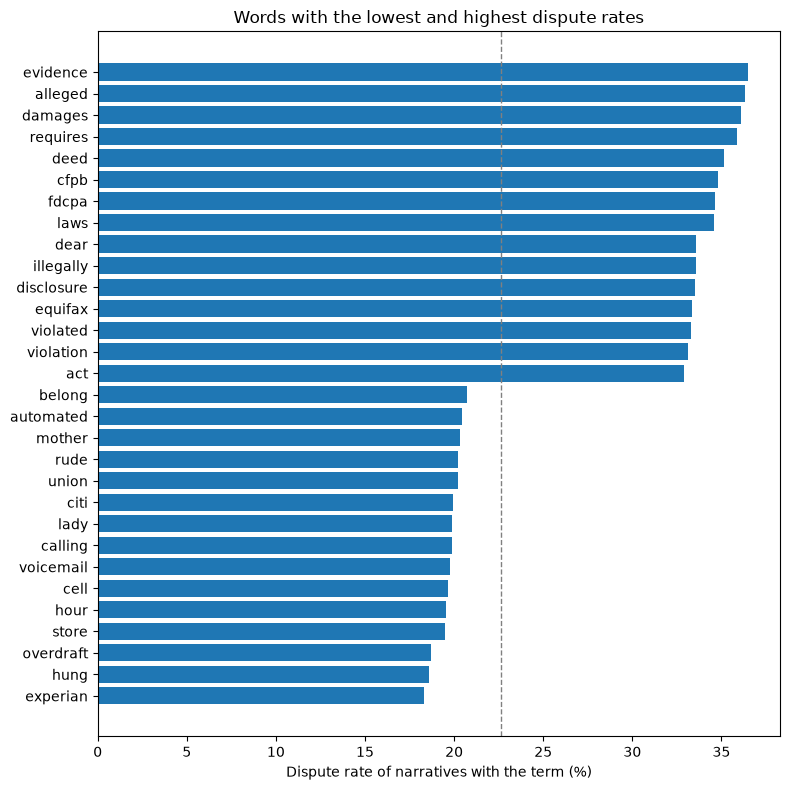

,narratives,dispute_rate
evidence,3003,0.365
alleged,2719,0.363
damages,1560,0.361
requires,1516,0.359
deed,2135,0.351
cfpb,6679,0.348
fdcpa,2499,0.346
laws,2803,0.346
dear,1649,0.336
illegally,1764,0.336


In [17]:
rate_chart(words, "Words with the lowest and highest dispute rates", "dispute_rate_words.png")

The highest rates go with legal and formal wording: evidence (36.5%), alleged, damages, fdcpa, laws, violation, and cfpb itself at 34.8%. The lowest go with phone calls (hung, voicemail, calling, rude) and everyday banking (overdraft, store). Two of the credit bureaus are at opposite ends, equifax at 33.4% and experian at 18.3%.

In [18]:
bureaus = df[df["company"].str.contains("equifax|experian|transunion", case=False)]
bureaus.groupby("company")["disputed"].agg(["size", "mean"]).round(3)

,size,mean
company,,
"EQUIFAX, INC.",10479,0.287
Experian Information Solutions Inc.,8416,0.153
"TRANSUNION INTERMEDIATE HOLDINGS, INC.",8232,0.189


That's the company's own rate showing up in the text. Equifax complaints are disputed 28.7% of the time, TransUnion's 18.9% and Experian's 15.3%, so some of what the words know is which company the complaint is about.

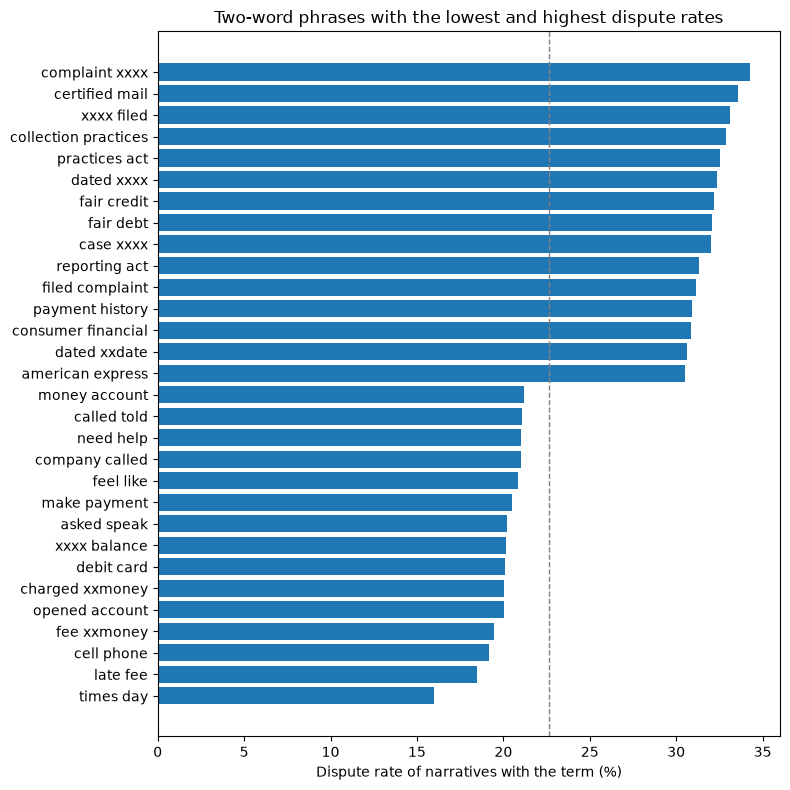

,narratives,dispute_rate
complaint xxxx,2330,0.343
certified mail,1860,0.335
xxxx filed,1533,0.331
collection practices,1879,0.329
practices act,1670,0.325
dated xxxx,2403,0.323
fair credit,2761,0.322
fair debt,1987,0.321
case xxxx,2181,0.320
reporting act,2470,0.313


In [19]:
rate_chart(phrases, "Two-word phrases with the lowest and highest dispute rates", "dispute_rate_phrases.png")

The phrases show the same thing. Certified mail (33.5%), the Fair Credit Reporting Act, the Fair Debt Collection Practices Act and references to a dated letter or a case number are at the top. At the bottom are `times day` (16.0%, mostly from calls "times a day"), late fees, cell phones and debit cards.

## Template letters

In [20]:
repeats = df[df["copies"] > 1]
len(repeats), repeats["text"].str.lower().nunique()

(4753, 1743)

In [21]:
pd.DataFrame(
    {
        "all": df["product"].value_counts(normalize=True),
        "repeated": repeats["product"].value_counts(normalize=True),
    }
).sort_values("repeated", ascending=False).head(5).round(3)

,all,repeated
product,,
Credit reporting,0.189,0.57
Debt collection,0.246,0.358
Credit card,0.116,0.028
Bank account or service,0.092,0.013
Consumer Loan,0.057,0.012


In [22]:
repeats["company"].value_counts().head(5)

company
Experian Information Solutions Inc.       957
EQUIFAX, INC.                             890
TRANSUNION INTERMEDIATE HOLDINGS, INC.    838
CAPITAL ONE FINANCIAL CORPORATION          94
Portfolio Recovery Associates, LLC         84
Name: count, dtype: int64[pyarrow]

In [23]:
letter = df[df["copies"] == df["copies"].max()]
print(letter["text"].iloc[0])
len(letter), letter["company"].unique(), letter["disputed"].sum()

I am filing this complaint because Experian has ignored my request to provide me with the documents that their company has on file that was used to verify the accounts I disputed. Being that they have gone past the 30 day mark and can not verify these accounts, under Section 611 ( 5 ) ( A ) of the FCRA - they are required to " ... promptly delete all information which can not be verified '' that I have disputed. Please resolve this manner as soon as possible. Thank you.


(103,
 <ArrowStringArray>
 ['Experian Information Solutions Inc.']
 Length: 1, dtype: string,
 np.int64(0))

4,753 complaints share their text with at least one other (1,743 different texts). 57% of them are credit reporting complaints and 36% debt collection, against 19% and 25% of all narratives, and the three credit bureaus received 2,685 of them. The most repeated one is a letter to Experian that quotes Section 611 of the FCRA. It was sent 103 times and never disputed.

Some letters are the same apart from a name or an account number, so they don't count as exact copies. Counting the narratives that start with the same 100 characters picks those up too.

In [24]:
opening = df["text"].str.lower().str[:100]
df["same_opening"] = opening.map(opening.value_counts())
(df["same_opening"] > 1).sum(), (df["same_opening"] >= 10).sum()

(np.int64(9828), np.int64(1282))

In [25]:
opening.value_counts().head(10)

text
i am filing this complaint because experian has ignored my request to provide me with the documents     133
this company continues to report on my credit report after i sent them a letter telling them that th    108
while checking my personal credit report, i noticed an unauthorized and fraudulent credit inquiry ma     89
i am filing this complaint because equifax has ignored my request to provide me with the documents t     84
i am filing this complaint because transunion has ignored my request to provide me with the document     81
while checking my personal credit report, i discovered an unauthorized and fraudulent credit inquiry     59
i filed a complaint stating that the public record information was inaccurate in its filing. as the      44
i was shocked when i reviewed my credit report and found late payment on the dates below : 30 days p     44
i am filing this complaint because equifax has ignored my request to open investigation in regards t     36
i have been a victim of

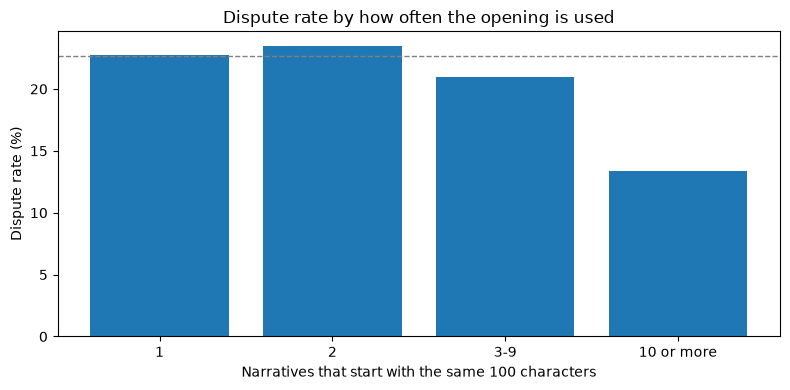

,size,mean
same_opening,,
1,139833,0.227
2,5102,0.235
3-9,3444,0.209
10 or more,1282,0.133


In [26]:
groups = pd.cut(df["same_opening"], [0, 1, 2, 9, 200], labels=["1", "2", "3-9", "10 or more"])
by_opening = df.groupby(groups, observed=True)["disputed"].agg(["size", "mean"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_opening.index, by_opening["mean"] * 100)
ax.axhline(overall * 100, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Narratives that start with the same 100 characters")
ax.set_ylabel("Dispute rate (%)")
ax.set_title("Dispute rate by how often the opening is used")
fig.tight_layout()
fig.savefig(FIGURES + "dispute_rate_by_opening.png", dpi=150)
plt.show()
by_opening.round(3)

9,828 narratives start the same way as at least one other, about twice the number of exact copies, and 1,282 use an opening that appears 10 times or more. Pairs are disputed about as often as one-off texts (23.5% against 22.7%). The drop comes with the mass letters, where openings used 10 times or more are disputed 13.3% of the time.

In [27]:
fcra = df["text"].str.contains("fcra", case=False)
df[fcra].groupby(df["same_opening"] >= 10)["disputed"].agg(["size", "mean"]).round(3)

,size,mean
same_opening,,
False,4196,0.346
True,350,0.060


Narratives that mention the FCRA are disputed 34.6% of the time when the opening is used fewer than 10 times, and 6.0% when it's one of the mass letters (350 narratives). The legal wording goes with disputes when the consumer wrote the complaint themselves, and a copied letter with the same wording goes the other way.